# 11. Improved Model Training — Controlled Fine-Tuning Experiment

This is the **final notebook in the notebook series**.

It starts from the trained Focal Loss checkpoint and runs a controlled fine-tuning experiment:
- MobileNetV2 backbone: unfreeze only the final convolutional layers.
- Batch Normalization layers remain frozen for stability on this small dataset.
- Lower learning rate for fine-tuning.
- Focal objectness loss with a positive-class alpha weight of 0.75.
- Saves to a new folder; baseline and Focal Loss checkpoints are never overwritten.
- Uses training and validation splits only. Test data is not used for training or model selection.

**Important:** This is a new experiment, not a guaranteed improvement. Compare its validation detection metrics with the existing models using the same evaluation pipeline before calling it better.


**Checkpoint output:** `models/improved_experiment/best_model_improved.keras`.

## 1. Imports and project paths

In [1]:
import os, sys, json, random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

PROJECT_ROOT = next(
    (p for p in [Path.cwd(), Path.cwd().parent]
     if (p / "src" / "data" / "dataset.py").exists()),
    None
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook from the project root or notebooks folder.")

sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT)

DATASET_PATH = PROJECT_ROOT / "data" / "NEU-DET"
MODELS_DIR = PROJECT_ROOT / "models"
FOCAL_DIR = MODELS_DIR / "focal_experiment"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "training"
FOCAL_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project:", PROJECT_ROOT)
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))


Project: d:\Industrial Surface Defect Detection and Classification Using CNN,Transfer Learning and Tensorflow
TensorFlow: 2.15.0
GPU: []


## 2. Fine-tuning configuration

In [2]:
IMAGE_SIZE = 224
GRID_SIZE = 7
NUM_CLASSES = 6
NUM_ANCHORS = 5
BATCH_SIZE = 8
EPOCHS = 20
LEARNING_RATE = 1e-5
PATIENCE = 5
OUTPUT_CHANNELS = 5 + NUM_CLASSES

# Fine-tune only the last backbone layers; keep BatchNorm layers frozen.
UNFREEZE_LAST_N = 30
POSITIVE_ALPHA = 0.75
FOCAL_GAMMA = 2.0
BOX_LOSS_WEIGHT = 5.0

CLASS_NAMES = [
    "crazing", "inclusion", "patches",
    "pitted_surface", "rolled-in_scale", "scratches"
]
INPUT_SHAPE = (IMAGE_SIZE, IMAGE_SIZE, 3)

print("Input:", INPUT_SHAPE)
print("Output:", (GRID_SIZE, GRID_SIZE, NUM_ANCHORS, OUTPUT_CHANNELS))
print("Fine-tuning last backbone layers:", UNFREEZE_LAST_N)


Input: (224, 224, 3)
Output: (7, 7, 5, 11)
Fine-tuning last backbone layers: 30


## 3. Load data splits

In [3]:
from src.data.dataset import get_dataset_splits

train, val, test = get_dataset_splits(str(DATASET_PATH))

print("Train:", len(train), "Validation:", len(val), "Test:", len(test))
print("Sample keys:", train[0].keys())
print("First image:", train[0]["image"])
print("First sample boxes:", np.asarray(train[0]["boxes"]).shape)
print("First sample labels:", np.asarray(train[0]["labels"]).shape)

assert len(train) and len(val) and len(test)

Train: 1151 Validation: 288 Test: 360
Sample keys: dict_keys(['image', 'boxes', 'labels', 'stratify'])
First image: d:\Industrial Surface Defect Detection and Classification Using CNN,Transfer Learning and Tensorflow\data\NEU-DET\train\images\rolled-in_scale\rolled-in_scale_32.jpg
First sample boxes: (1, 4)
First sample labels: (1,)


## 4. Load the saved anchors

In [4]:
ANCHORS_PATH = MODELS_DIR / "anchors.npy"
if not ANCHORS_PATH.exists():
    raise FileNotFoundError(f"Missing {ANCHORS_PATH}. Generate anchors in your previous workflow.")

anchors = np.load(ANCHORS_PATH).astype(np.float32)
assert anchors.shape == (NUM_ANCHORS, 2), anchors.shape
assert np.all(anchors > 0)
print(anchors)

[[0.1828321  0.24619976]
 [0.28540698 0.51598006]
 [0.21671906 0.910609  ]
 [0.6913246  0.32715988]
 [0.81677145 0.9229429 ]]


## 5. Anchor IoU and target encoding

In [5]:
def calculate_anchor_iou(width, height, anchors_array):
    inter_w = np.minimum(width, anchors_array[:, 0])
    inter_h = np.minimum(height, anchors_array[:, 1])
    intersection = inter_w * inter_h
    union = width * height + anchors_array[:, 0] * anchors_array[:, 1] - intersection
    return intersection / np.maximum(union, 1e-9)


def encode_targets(boxes, labels, anchors_array):
    target = np.zeros(
        (GRID_SIZE, GRID_SIZE, NUM_ANCHORS, OUTPUT_CHANNELS),
        dtype=np.float32
    )
    assigned = set()

    for box, label in zip(boxes, labels):
        xmin, ymin, xmax, ymax = map(float, box)
        label = int(label)

        if not (0 <= xmin < xmax <= 1 and 0 <= ymin < ymax <= 1):
            raise ValueError(f"Invalid normalized box: {box}")
        if not 0 <= label < NUM_CLASSES:
            raise ValueError(f"Invalid class ID: {label}")

        cx, cy = (xmin + xmax) / 2, (ymin + ymax) / 2
        width, height = xmax - xmin, ymax - ymin
        cell_x = min(int(cx * GRID_SIZE), GRID_SIZE - 1)
        cell_y = min(int(cy * GRID_SIZE), GRID_SIZE - 1)

        ious = calculate_anchor_iou(width, height, anchors_array)
        chosen = None
        for anchor_id in np.argsort(ious)[::-1]:
            key = (cell_y, cell_x, int(anchor_id))
            if key not in assigned:
                assigned.add(key)
                chosen = int(anchor_id)
                break

        if chosen is None:
            raise ValueError(f"No free anchor in grid cell ({cell_y}, {cell_x}).")

        aw, ah = anchors_array[chosen]
        tx = cx * GRID_SIZE - cell_x
        ty = cy * GRID_SIZE - cell_y
        tw = np.log(width / aw)
        th = np.log(height / ah)

        target[cell_y, cell_x, chosen, 0:4] = [tx, ty, tw, th]
        target[cell_y, cell_x, chosen, 4] = 1.0
        target[cell_y, cell_x, chosen, 5 + label] = 1.0

    return target


check_target = encode_targets(train[0]["boxes"], train[0]["labels"], anchors)
print("Target shape:", check_target.shape)
print("Positive anchors:", int(check_target[..., 4].sum()))
print("GT boxes:", len(train[0]["boxes"]))
assert check_target.shape == (7, 7, 5, 11)
assert int(check_target[..., 4].sum()) == len(train[0]["boxes"])

Target shape: (7, 7, 5, 11)
Positive anchors: 1
GT boxes: 1


## 6. Image preprocessing and data pipelines

In [6]:
def load_image(path):
    raw = tf.io.read_file(path)
    image = tf.io.decode_image(raw, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, [IMAGE_SIZE, IMAGE_SIZE])
    image = tf.cast(image, tf.float32)
    return tf.keras.applications.mobilenet_v2.preprocess_input(image)


def generator(samples):
    for sample in samples:
        image = load_image(str(sample["image"]))
        target = encode_targets(sample["boxes"], sample["labels"], anchors)
        yield image, target


signature = (
    tf.TensorSpec((IMAGE_SIZE, IMAGE_SIZE, 3), tf.float32),
    tf.TensorSpec((GRID_SIZE, GRID_SIZE, NUM_ANCHORS, OUTPUT_CHANNELS), tf.float32)
)

def make_dataset(samples, training=False):
    ds = tf.data.Dataset.from_generator(
        lambda: generator(samples),
        output_signature=signature
    )
    if training:
        ds = ds.shuffle(min(len(samples), 1000), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(train, training=True)
val_ds = make_dataset(val, training=False)

for image_batch, target_batch in train_ds.take(1):
    print("Image batch:", image_batch.shape)
    print("Target batch:", target_batch.shape)

Image batch: (8, 224, 224, 3)
Target batch: (8, 7, 7, 5, 11)


## 7. Load the Focal Loss checkpoint and unfreeze selected backbone layers

This experiment initializes from `models/focal_experiment/best_model_focal.keras`. It does not load or overwrite the baseline checkpoint.

In [7]:
FOCAL_PATH = FOCAL_DIR / "best_model_focal.keras"
IMPROVED_DIR = MODELS_DIR / "improved_experiment"
IMPROVED_DIR.mkdir(parents=True, exist_ok=True)

if not FOCAL_PATH.exists():
    raise FileNotFoundError(
        f"Focal Loss checkpoint not found: {FOCAL_PATH}. "
        "Complete Notebook 06 Focal Loss experiment first."
    )

model = tf.keras.models.load_model(FOCAL_PATH, compile=False)
print("Loaded Focal Loss initialization:", FOCAL_PATH)

expected_shape = (GRID_SIZE, GRID_SIZE, NUM_ANCHORS, OUTPUT_CHANNELS)
assert tuple(model.output_shape[1:]) == expected_shape, model.output_shape

# Locate the nested MobileNetV2 backbone.
backbones = [
    layer for layer in model.layers
    if isinstance(layer, tf.keras.Model) and "mobilenetv2" in layer.name.lower()
]
if not backbones:
    print("Top-level layers:", [(layer.name, type(layer).__name__) for layer in model.layers])
    raise RuntimeError(
        "Could not locate nested MobileNetV2 backbone. Inspect the printed layer list "
        "and do not continue until the backbone is identified."
    )

backbone = backbones[0]
backbone.trainable = True

# Freeze all backbone layers first, then unfreeze only the final N non-BatchNorm layers.
for layer in backbone.layers:
    layer.trainable = False

eligible = [
    layer for layer in backbone.layers
    if not isinstance(layer, tf.keras.layers.BatchNormalization)
]
for layer in eligible[-UNFREEZE_LAST_N:]:
    layer.trainable = True

# Keep Batch Normalization layers frozen to avoid unstable moving statistics.
for layer in backbone.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

# Ensure the detector head remains trainable.
for layer in model.layers:
    if layer.name != backbone.name and not isinstance(layer, tf.keras.Model):
        layer.trainable = True

trainable_count = sum(int(np.prod(v.shape)) for v in model.trainable_variables)
total_count = sum(int(np.prod(v.shape)) for v in model.variables)
print("Output shape:", model.output_shape)
print("Trainable parameters:", trainable_count)
print("Total parameters:", total_count)
print("Trainable backbone layers:", sum(1 for l in backbone.layers if l.trainable))




Loaded Focal Loss initialization: d:\Industrial Surface Defect Detection and Classification Using CNN,Transfer Learning and Tensorflow\models\focal_experiment\best_model_focal.keras
Output shape: (None, 7, 7, 5, 11)
Trainable parameters: 4975863
Total parameters: 5510519
Trainable backbone layers: 30


## 8. Focal Loss with stronger positive-objectness weighting

The positive anchors are rare. This experiment sets `alpha=0.75` for positive objectness targets and `0.25` for negatives. Positive and negative terms are averaged separately, as in the prior experiment.

In [8]:
def detector_loss_focal(y_true, y_pred, alpha=POSITIVE_ALPHA, gamma=FOCAL_GAMMA):
    positive_mask = y_true[..., 4:5]

    # Smooth L1 box regression on positive anchors.
    box_true = y_true[..., 0:4]
    box_pred = y_pred[..., 0:4]
    diff = tf.abs(box_true - box_pred)
    smooth_l1 = tf.where(diff < 1.0, 0.5 * tf.square(diff), diff - 0.5)

    positive_count = tf.reduce_sum(positive_mask)
    box_loss = tf.reduce_sum(smooth_l1 * positive_mask) / tf.maximum(
        positive_count * 4.0, 1.0
    )

    # Sigmoid focal loss for objectness.
    obj_true = y_true[..., 4:5]
    obj_logits = y_pred[..., 4:5]
    probability = tf.sigmoid(obj_logits)
    bce = tf.nn.sigmoid_cross_entropy_with_logits(
        labels=obj_true, logits=obj_logits
    )

    p_t = obj_true * probability + (1.0 - obj_true) * (1.0 - probability)
    alpha_t = obj_true * alpha + (1.0 - obj_true) * (1.0 - alpha)
    focal = alpha_t * tf.pow(1.0 - p_t, gamma) * bce

    negative_mask = 1.0 - positive_mask
    positive_obj = tf.reduce_sum(focal * positive_mask) / tf.maximum(
        tf.reduce_sum(positive_mask), 1.0
    )
    negative_obj = tf.reduce_sum(focal * negative_mask) / tf.maximum(
        tf.reduce_sum(negative_mask), 1.0
    )
    objectness_loss = positive_obj + negative_obj

    # Softmax classification on positive anchors.
    class_ce = tf.nn.softmax_cross_entropy_with_logits(
        labels=y_true[..., 5:], logits=y_pred[..., 5:]
    )
    class_loss = tf.reduce_sum(
        class_ce * tf.squeeze(positive_mask, axis=-1)
    ) / tf.maximum(positive_count, 1.0)

    total = BOX_LOSS_WEIGHT * box_loss + objectness_loss + class_loss
    return total, box_loss, objectness_loss, class_loss


print("Focal loss defined.")

Focal loss defined.


## 9. Fine-tuning optimizer and training steps

A low learning rate is used to reduce destructive updates to pretrained features.

In [9]:
optimizer = tf.keras.optimizers.Adam(
    learning_rate=LEARNING_RATE,
    clipnorm=1.0
)

@tf.function
def train_step(images, targets):
    with tf.GradientTape() as tape:
        predictions = model(images, training=True)
        total, box, obj, cls = detector_loss_focal(targets, predictions)

    variables = model.trainable_variables
    gradients = tape.gradient(total, variables)
    pairs = [(g, v) for g, v in zip(gradients, variables) if g is not None]
    optimizer.apply_gradients(pairs)
    return total, box, obj, cls

@tf.function
def validation_step(images, targets):
    predictions = model(images, training=False)
    return detector_loss_focal(targets, predictions)

print("Fine-tuning uses Focal Loss with positive alpha =", POSITIVE_ALPHA)
print("Learning rate:", LEARNING_RATE)


Fine-tuning uses Focal Loss with positive alpha = 0.75
Learning rate: 1e-05


## 10. Train and save the improved experiment checkpoint

The new checkpoint is saved separately under `models/improved_experiment/`.

In [10]:
best_model_path = IMPROVED_DIR / "best_model_improved.keras"

history = {
    "train_loss": [], "val_loss": [],
    "box_loss": [], "objectness_loss": [], "class_loss": []
}
best_val_loss = float("inf")
wait = 0

for epoch in range(EPOCHS):
    train_losses, val_losses, components = [], [], []
    print(f"\\nEpoch {epoch + 1}/{EPOCHS}")

    for images, targets in train_ds:
        total, box, obj, cls = train_step(images, targets)
        train_losses.append(float(total.numpy()))
        components.append([float(box.numpy()), float(obj.numpy()), float(cls.numpy())])

    for images, targets in val_ds:
        total, _, _, _ = validation_step(images, targets)
        val_losses.append(float(total.numpy()))

    train_loss = float(np.mean(train_losses))
    val_loss = float(np.mean(val_losses))
    comp = np.mean(components, axis=0)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["box_loss"].append(float(comp[0]))
    history["objectness_loss"].append(float(comp[1]))
    history["class_loss"].append(float(comp[2]))

    print(f"Training loss: {train_loss:.4f}")
    print(f"Validation loss: {val_loss:.4f}")
    print(f"Box: {comp[0]:.4f} | Objectness: {comp[1]:.4f} | Class: {comp[2]:.4f}")

    if np.isfinite(val_loss) and val_loss < best_val_loss:
        best_val_loss = val_loss
        wait = 0
        model.save(best_model_path)
        print("Best Focal checkpoint saved:", best_model_path)
    else:
        wait += 1
        print(f"No improvement: {wait}/{PATIENCE}")
        if wait >= PATIENCE:
            print("Early stopping.")
            break

if not best_model_path.exists():
    raise RuntimeError("Focal checkpoint was not saved. Check validation losses.")

print("Training complete. Best validation loss:", best_val_loss)
print("Checkpoint:", best_model_path)

\nEpoch 1/20
Training loss: 0.0893
Validation loss: 0.6910
Box: 0.0105 | Objectness: 0.0314 | Class: 0.0053
Best Focal checkpoint saved: d:\Industrial Surface Defect Detection and Classification Using CNN,Transfer Learning and Tensorflow\models\improved_experiment\best_model_improved.keras
\nEpoch 2/20
Training loss: 0.0627
Validation loss: 0.6656
Box: 0.0066 | Objectness: 0.0256 | Class: 0.0043
Best Focal checkpoint saved: d:\Industrial Surface Defect Detection and Classification Using CNN,Transfer Learning and Tensorflow\models\improved_experiment\best_model_improved.keras
\nEpoch 3/20
Training loss: 0.0548
Validation loss: 0.6543
Box: 0.0052 | Objectness: 0.0241 | Class: 0.0046
Best Focal checkpoint saved: d:\Industrial Surface Defect Detection and Classification Using CNN,Transfer Learning and Tensorflow\models\improved_experiment\best_model_improved.keras
\nEpoch 4/20
Training loss: 0.0488
Validation loss: 0.6668
Box: 0.0044 | Objectness: 0.0228 | Class: 0.0038
No improvement: 1/5

## 11. Plot and save training history

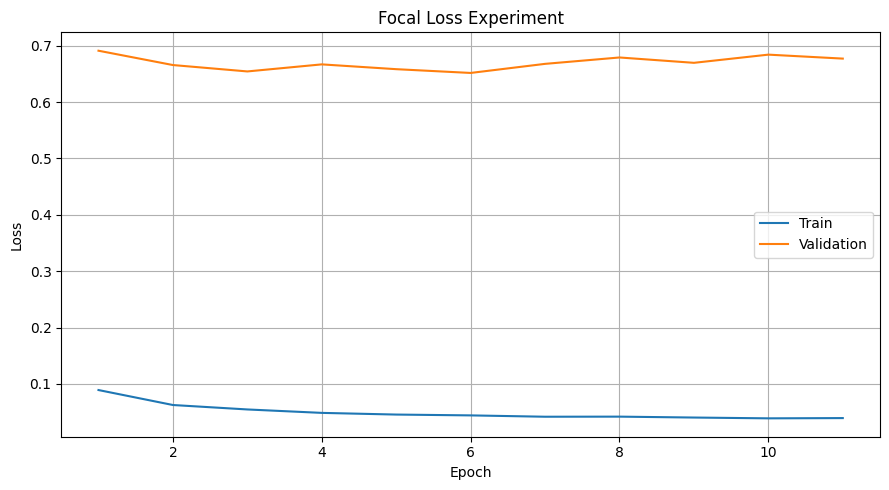

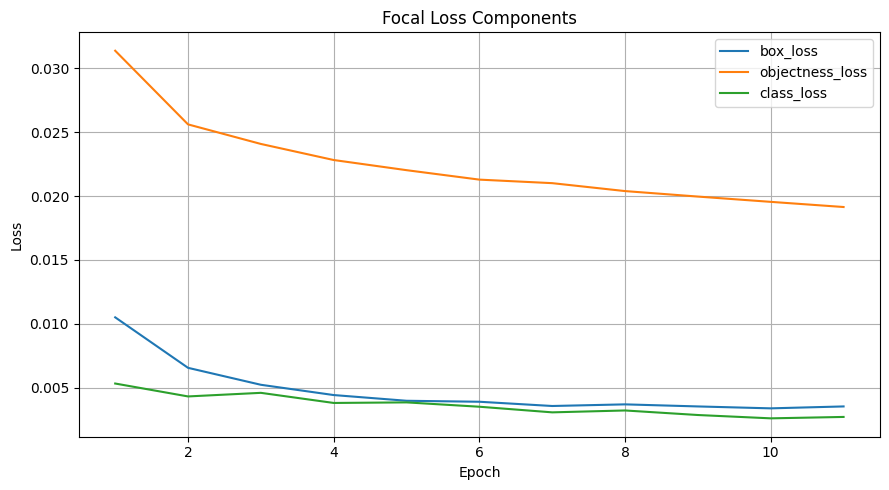

experiment                                           Focal Loss objectness
epochs_completed                                                        11
best_epoch                                                               6
best_validation_loss                                               0.65161
final_training_loss                                               0.039522
final_validation_loss                                              0.67705
checkpoint               d:\Industrial Surface Defect Detection and Cla...
classes                  [crazing, inclusion, patches, pitted_surface, ...
anchors                  [[0.18283210694789886, 0.24619975686073303], [...
dtype: object


In [11]:
epochs_ran = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(9, 5))
plt.plot(epochs_ran, history["train_loss"], label="Train")
plt.plot(epochs_ran, history["val_loss"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Focal Loss Experiment")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "improved_training_loss.png", dpi=150)
plt.show()

plt.figure(figsize=(9, 5))
for key in ["box_loss", "objectness_loss", "class_loss"]:
    plt.plot(epochs_ran, history[key], label=key)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Focal Loss Components")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "improved_loss_components.png", dpi=150)
plt.show()

history_df = pd.DataFrame(history)
history_df.to_csv(OUTPUT_DIR / "improved_training_history.csv", index_label="epoch")
best_epoch = int(np.argmin(history["val_loss"])) + 1
summary = {
    "experiment": "Focal Loss objectness",
    "epochs_completed": len(history["train_loss"]),
    "best_epoch": best_epoch,
    "best_validation_loss": float(min(history["val_loss"])),
    "final_training_loss": float(history["train_loss"][-1]),
    "final_validation_loss": float(history["val_loss"][-1]),
    "checkpoint": str(best_model_path),
    "classes": CLASS_NAMES,
    "anchors": anchors.tolist()
}
(OUTPUT_DIR / "improved_training_summary.json").write_text(
    json.dumps(summary, indent=2), encoding="utf-8"
)
print(pd.Series(summary))

## 12. Verify checkpoint and preserve baseline

In [13]:
# Define checkpoint paths
BASELINE_PATH = MODELS_DIR / "best_model.keras"
FOCAL_PATH = FOCAL_DIR / "best_model_focal.keras"

# Load improved model
improved_model = tf.keras.models.load_model(
    best_model_path,
    compile=False
)

print("Improved checkpoint exists:", best_model_path.exists())
print("Improved checkpoint size:", best_model_path.stat().st_size, "bytes")
print("Improved output shape:", improved_model.output_shape)

print("Original baseline still exists:", BASELINE_PATH.exists())
print("Focal checkpoint still exists:", FOCAL_PATH.exists())

assert tuple(improved_model.output_shape[1:]) == (7, 7, 5, 11)
assert BASELINE_PATH.exists()
assert FOCAL_PATH.exists()

print("Notebook 11 verification completed successfully!")

Improved checkpoint exists: True
Improved checkpoint size: 22573069 bytes
Improved output shape: (None, 7, 7, 5, 11)
Original baseline still exists: True
Focal checkpoint still exists: True
Notebook 11 verification completed successfully!
